# 02 | Pipelines and Models
*Project 2 — Machine Learning: From Data to Predictions*
# Project 2 — Predicting PEM Fuel-Cell Cell Voltage
## Notebook 2 of 3: Pipelines, fair model comparison, and tuning

**Goal:** Build leakage-safe preprocessing and regression pipelines, compare model families fairly, tune the strongest candidate using training data only, and document the final model choice.

This notebook compares the mean baseline with three deliberately different model families: regularized linear regression, Random Forest, and Extra Trees. All candidates use identical group-aware folds and the same MAE metric. Means and fold-to-fold standard deviations are reported so small differences are not overstated. Every learned preprocessing operation is inside the pipeline. This notebook follows the second template stage. The held-out test files are not used to choose the model or its hyperparameters.

---
## 0. Setup

In [1]:
from pathlib import Path
import sys, warnings, json
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from project_utils import load_polarization_data

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
FEATURES = ["current_density", "pressure", "relative_humidity", "test_family", "operating_set"]
TARGET = "cell_voltage"
GROUP = "source_file"

data = load_polarization_data()
print(f"Loaded {len(data):,} observations from {data[GROUP].nunique()} source files "
      f"across {data['test_family'].nunique()} test families.")

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

Loaded 5,005 observations from 26 source files across 9 test families.


---
## 1. Load and split - Train/test split by complete source file

Recreate the same deterministic source-file split used in notebook 01. Assert that no source file is shared between training and test partitions. Model selection below uses only `train`.
A random row split would place neighboring points from the same measured curve in both sets and produce optimistic scores. Instead, one grouped split creates a final untouched test set.

In [2]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.22, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(data, data[TARGET], groups=data[GROUP]))
train, test = data.iloc[train_idx].copy(), data.iloc[test_idx].copy()
assert set(train[GROUP]).isdisjoint(set(test[GROUP]))
X_train, y_train = train[FEATURES], train[TARGET]
print(f"Training rows/files: {len(train):,}/{train[GROUP].nunique()}")
print(f"Held-out rows/files: {len(test):,}/{test[GROUP].nunique()}")
print("Overlap:", set(train[GROUP]) & set(test[GROUP]))
cv = GroupKFold(n_splits=min(3, train[GROUP].nunique()))

Training rows/files: 3,692/20
Held-out rows/files: 1,313/6
Overlap: set()


---
## 2. Preprocessing and model pipeline

All learned preprocessing belongs inside a `Pipeline` and `ColumnTransformer`. This ensures imputation, scaling, and one-hot encoding are fitted separately inside each training fold. Unknown categories in validation folds are handled without failing. Note that numeric and categorical fields use separate transformations.

In [3]:
NUMERIC = ["current_density", "pressure", "relative_humidity"]
CATEGORICAL = ["test_family", "operating_set"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("cat", categorical_pipe, CATEGORICAL)
])

print("Numeric features:", NUMERIC)
print("Categorical features:", CATEGORICAL)
print("All features:", FEATURES)
print("Target:", TARGET)

Numeric features: ['current_density', 'pressure', 'relative_humidity']
Categorical features: ['test_family', 'operating_set']
All features: ['current_density', 'pressure', 'relative_humidity', 'test_family', 'operating_set']
Target: cell_voltage


---
## 3. First model in the pipeline

Use a mean-prediction baseline as a reference and Ridge regression as a simple linear model. Both are scored with the same grouped folds and MAE/RMSE/R² metrics.

In [4]:
# Use one stable colour per model throughout every comparison plot.
# This mapping is reused for the single-metric plots and the dashboard so the
# audience can recognize a model immediately across slides and notebooks.
MODEL_COLORS = {
    "Mean baseline": "#FF0000",       # red: reference benchmark
    "Ridge regression": "#0000FF",    # blue: linear model
    "Random Forest": "#008000",      # green: bagged decision trees
    "Extra Trees": "#90EE90",         # light green: randomized tree ensemble
    "Gradient Boosting": "#FFA500",   # orange: sequential boosting ensemble
    "Tuned Random Forest": "#006400",# dark green: tuned version of Random Forest
}

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ridge regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=120, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=120, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, max_depth=2, random_state=RANDOM_STATE),
}

rows = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
    scores = cross_validate(
        pipe, X_train, y_train, groups=train[GROUP], cv=cv, n_jobs=1,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error", "r2": "r2"}
    )
    rows.append({
        "model": name,
        "MAE_V_mean": -scores["test_mae"].mean(),
        "MAE_V_std": scores["test_mae"].std(ddof=1),
        "RMSE_V_mean": -scores["test_rmse"].mean(),
        "RMSE_V_std": scores["test_rmse"].std(ddof=1),
        "R2_mean": scores["test_r2"].mean(),
        "R2_std": scores["test_r2"].std(ddof=1),
    })

comparison = pd.DataFrame(rows).sort_values("MAE_V_mean")
display(comparison.round(5))
comparison.to_csv(ROOT / "results_model_comparison.csv", index=False)

,model,MAE_V_mean,MAE_V_std,RMSE_V_mean,RMSE_V_std,R2_mean,R2_std
4,Gradient Boosting,0.08419,0.00434,0.11888,0.00233,0.72948,0.01389
2,Random Forest,0.08842,0.00916,0.13283,0.00867,0.66108,0.04947
3,Extra Trees,0.08934,0.01409,0.13584,0.01467,0.64359,0.08289
1,Ridge regression,0.14499,0.01114,0.18671,0.01192,0.33145,0.08332
0,Mean baseline,0.19817,0.00146,0.22866,0.00143,-0.00025,0.00021


---
## 4. Features

The feature set is kept consistent across models so the comparison isolates differences in the regression algorithms rather than changing the input information.

- `current_density`: position along the polarization curve.
- `pressure` and `relative_humidity`: recorded operating conditions where available.
- `test_family` and `operating_set`: categorical experimental context.
- `source_file`: used only for group-aware splitting and diagnostics.
- `power_density`: excluded because it is derived using cell voltage and current density and could leak target information.

Preprocessing handles missing values within each training fold; there is no target encoding or feature selection based on the held-out test set.

---
## 5. Compare models

All candidates use the same GroupKFold splits. Lower MAE and RMSE are better; higher R² is better. The standard deviations show fold-to-fold variability and help avoid overinterpreting small differences.

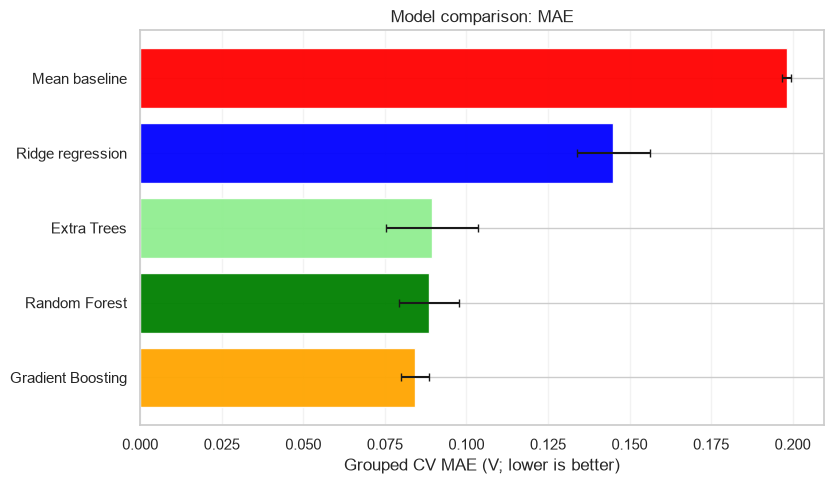

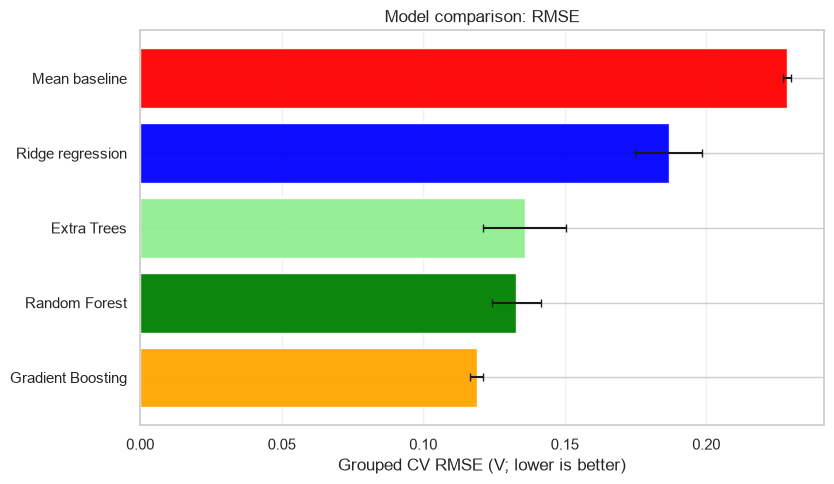

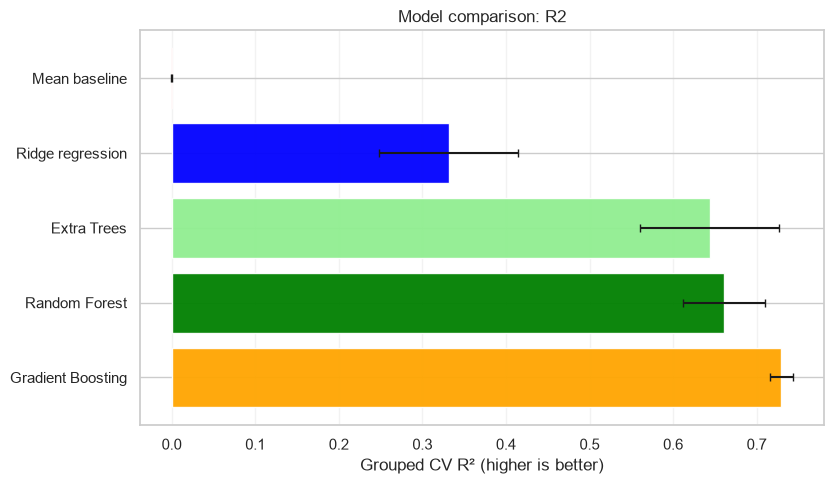

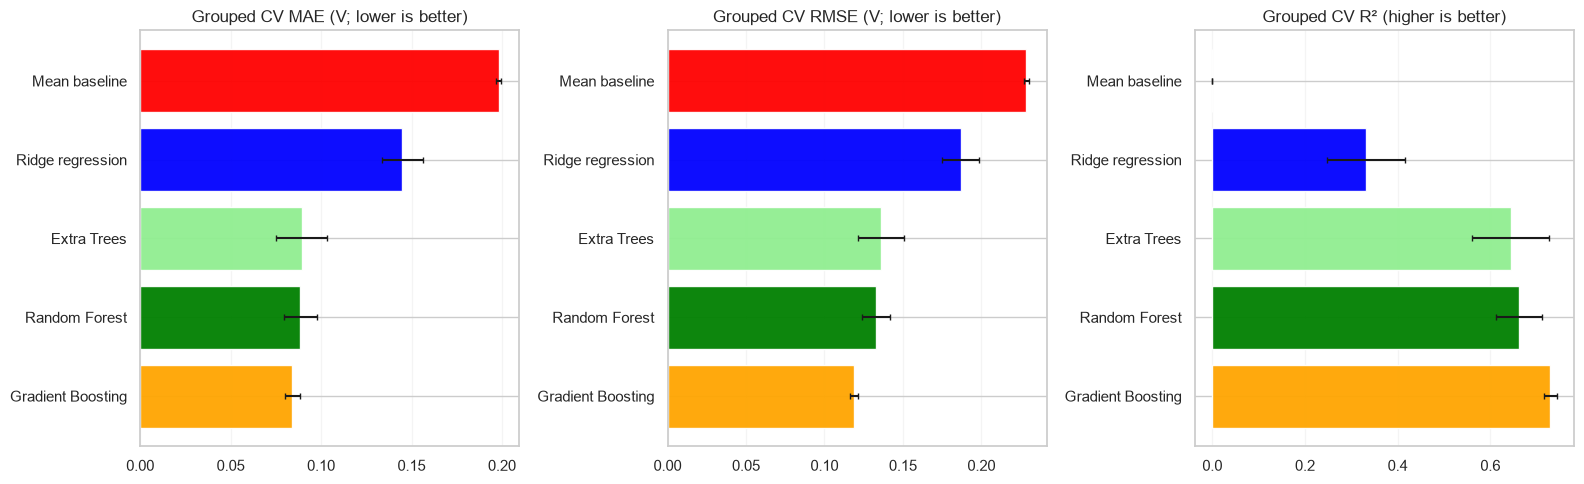

Saved grouped-CV comparison table and consistently colour-coded MAE, RMSE, R², and dashboard figures.


In [5]:
# Create separate, high-resolution figures for presentation slides.
metric_specs = [
    ("MAE_V", "Grouped CV MAE (V; lower is better)", "model_comparison_cv_mae.png", True),
    ("RMSE_V", "Grouped CV RMSE (V; lower is better)", "model_comparison_cv_rmse.png", True),
    ("R2", "Grouped CV R² (higher is better)", "model_comparison_cv_r2.png", False),
]
for metric, xlabel, filename, lower_better in metric_specs:
    plot_df = comparison.sort_values(f"{metric}_mean", ascending=lower_better)
    colors = [MODEL_COLORS.get(name, "#333333") for name in plot_df["model"]]
    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.barh(plot_df["model"], plot_df[f"{metric}_mean"], color=colors,
            xerr=plot_df[f"{metric}_std"], capsize=3, alpha=0.95)
    ax.set(xlabel=xlabel, title=f"Model comparison: {metric.replace('_V', '')}")
    ax.grid(axis="x", alpha=.25)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(ROOT / filename, dpi=220, bbox_inches="tight")
    plt.show()

# One compact multi-panel figure uses the same model colours in every panel.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (metric, title, _, lower_better) in zip(axes, metric_specs):
    plot_df = comparison.sort_values(f"{metric}_mean", ascending=lower_better)
    colors = [MODEL_COLORS.get(name, "#333333") for name in plot_df["model"]]
    ax.barh(plot_df["model"], plot_df[f"{metric}_mean"], color=colors,
            xerr=plot_df[f"{metric}_std"], capsize=2, alpha=0.95)
    ax.set_title(title)
    ax.grid(axis="x", alpha=.2)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(ROOT / "model_comparison_cv_dashboard.png", dpi=220, bbox_inches="tight")
plt.show()
print("Saved grouped-CV comparison table and consistently colour-coded MAE, RMSE, R², and dashboard figures.")

---
## 6. Tune Random Forest and compare its search candidates

Tune a Random Forest with `RandomizedSearchCV` and grouped folds. This search is intentionally modest for reproducibility. The scorer is negative MAE because scikit-learn maximizes scores; the reported MAE is converted back to a positive value. All tuning uses the training partition only.

The grouped-CV comparison is used to understand several model families. This project also tunes Random Forest explicitly so its untuned and tuned versions can be compared directly. The best mean CV score from a hyperparameter search is subject to selection optimism, so the untouched grouped holdout in Notebook 3 remains the more important final generalization check. A model with the lowest mean CV MAE is not automatically the best choice if fold variability, RMSE, R², or holdout results tell a different story.

Best grouped-CV MAE (V): 0.08505
Best parameters: {'model__n_estimators': 40, 'model__min_samples_leaf': 4, 'model__max_features': 0.8, 'model__max_depth': 16}


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
1,1,-0.085053,0.007804,-0.037526,"{'model__n_estimators': 40, 'model__min_sample..."
2,2,-0.086075,0.007626,-0.037683,"{'model__n_estimators': 25, 'model__min_sample..."
0,3,-0.086761,0.006424,-0.035578,"{'model__n_estimators': 40, 'model__min_sample..."


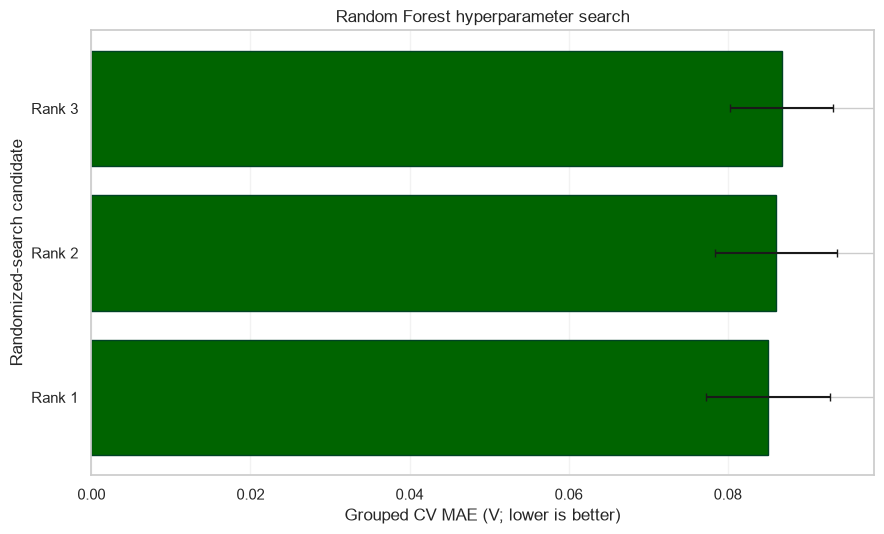

Saved best_model.joblib, tuning_results.csv, and random_forest_tuning_results.png.


In [6]:
param_dist = {
    "model__n_estimators": [25, 40, 60],
    "model__max_depth": [None, 10, 16],
    "model__min_samples_leaf": [2, 4, 8],
    "model__max_features": [1.0, 0.8],
}
tuning_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
])
search = RandomizedSearchCV(
    tuning_pipe, param_distributions=param_dist, n_iter=3,
    scoring="neg_mean_absolute_error", cv=cv, random_state=RANDOM_STATE,
    n_jobs=1, refit=True, return_train_score=True
)
search.fit(X_train, y_train, groups=train[GROUP])

# Plot all randomized-search candidates.
# Error bars show fold-to-fold score variability.

tuning_table = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
tuning_table["cv_MAE_V"] = -tuning_table["mean_test_score"]
tuning_table["cv_MAE_std_V"] = tuning_table["std_test_score"]
print("Best grouped-CV MAE (V):", round(-search.best_score_, 5))
print("Best parameters:", search.best_params_)
display(tuning_table[["rank_test_score", "mean_test_score", "std_test_score",
                      "mean_train_score", "params"]])
tuning_table.to_csv(ROOT / "tuning_results.csv", index=False)
joblib.dump(search.best_estimator_, ROOT / "best_model.joblib")

plot_tuning = tuning_table.sort_values("cv_MAE_V", ascending=True).reset_index(drop=True)
labels = [f"Rank {int(r)}" for r in plot_tuning["rank_test_score"]]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(labels, plot_tuning["cv_MAE_V"], xerr=plot_tuning["cv_MAE_std_V"],
        capsize=3, color=MODEL_COLORS["Tuned Random Forest"], edgecolor="#004225")
ax.set(xlabel="Grouped CV MAE (V; lower is better)",
       ylabel="Randomized-search candidate", title="Random Forest hyperparameter search")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / "random_forest_tuning_results.png", dpi=220, bbox_inches="tight")
plt.show()
print(
    "Saved best_model.joblib, tuning_results.csv, "
    "and random_forest_tuning_results.png."
)

Best grouped-CV MAE (V): 0.08505
Best parameters: {'model__n_estimators': 40, 'model__min_samples_leaf': 4, 'model__max_features': 0.8, 'model__max_depth': 16}


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
1,1,-0.085053,0.007804,-0.037526,"{'model__n_estimators': 40, 'model__min_sample..."
2,2,-0.086075,0.007626,-0.037683,"{'model__n_estimators': 25, 'model__min_sample..."
0,3,-0.086761,0.006424,-0.035578,"{'model__n_estimators': 40, 'model__min_sample..."


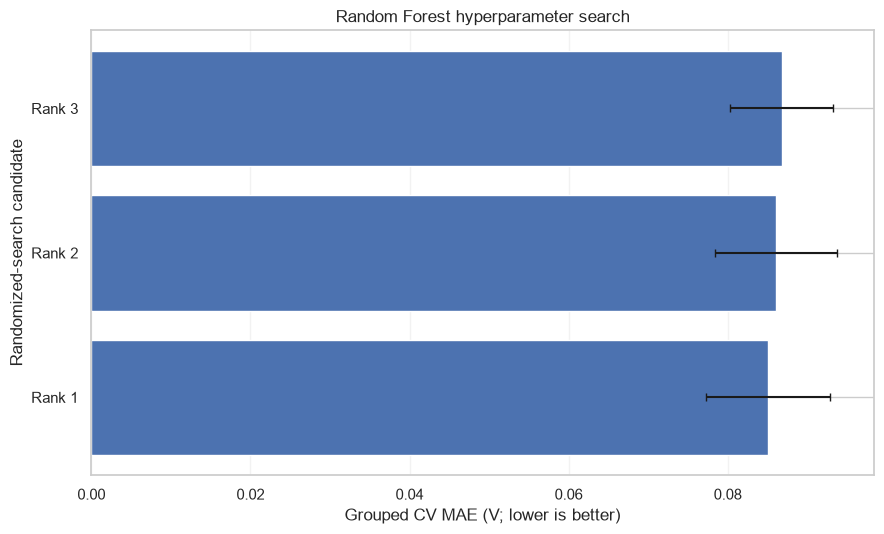

Saved best_model.joblib, tuning_results.csv, and random_forest_tuning_results.png.


In [7]:
param_dist = {
    "model__n_estimators": [25, 40, 60],
    "model__max_depth": [None, 10, 16],
    "model__min_samples_leaf": [2, 4, 8],
    "model__max_features": [1.0, 0.8],
}
tuning_pipe = Pipeline([("preprocess", preprocess),
                        ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))])
search = RandomizedSearchCV(tuning_pipe, param_distributions=param_dist, n_iter=3,
                            scoring="neg_mean_absolute_error", cv=cv, random_state=RANDOM_STATE,
                            n_jobs=1, refit=True, return_train_score=True)
search.fit(X_train, y_train, groups=train[GROUP])
tuning_table = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
print("Best grouped-CV MAE (V):", round(-search.best_score_, 5))
print("Best parameters:", search.best_params_)
display(tuning_table[["rank_test_score", "mean_test_score", "std_test_score", "mean_train_score", "params"]].head(8))
joblib.dump(search.best_estimator_, ROOT / "best_model.joblib")
tuning_table.to_csv(ROOT / "tuning_results.csv", index=False)

# Plot all randomized-search candidates. Error bars show fold-to-fold score variability.
tuning_table["cv_MAE_V"] = -tuning_table["mean_test_score"]
tuning_table["cv_MAE_std_V"] = tuning_table["std_test_score"]
plot_tuning = tuning_table.sort_values("cv_MAE_V", ascending=True).reset_index(drop=True)
MODEL_COLORS = {
    "Mean baseline": "#FF0000",       # red: reference benchmark
    "Ridge regression": "#0000FF",    # blue: linear model
    "Random Forest": "#008000",      # green: bagged decision trees
    "Extra Trees": "#90EE90",         # light green: randomized tree ensemble
    "Gradient Boosting": "#FFA500",   # orange: sequential boosting ensemble
    "Tuned Random Forest": "#006400",# dark blue: tuned version of Random Forest
}
fig, ax = plt.subplots(figsize=(9, 5.5))
labels = [f"Rank {int(r)}" for r in plot_tuning["rank_test_score"]]
ax.barh(labels, plot_tuning["cv_MAE_V"], xerr=plot_tuning["cv_MAE_std_V"], capsize=3)
ax.set(xlabel="Grouped CV MAE (V; lower is better)", ylabel="Randomized-search candidate",
       title="Random Forest hyperparameter search")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / "random_forest_tuning_results.png", dpi=220, bbox_inches="tight")
plt.show()
print("Saved best_model.joblib, tuning_results.csv, and random_forest_tuning_results.png.")

---
## 7. Threshold

This is a regression problem, not classification. There is no class-probability threshold to select. The model predicts a continuous cell-voltage value, and its performance is evaluated using MAE, RMSE, and R².

---
## 8. The final model -validation checkpoint

The selected final pipeline is the best Random Forest candidate under grouped cross-validation on the training data. Its hyperparameters and pipeline are saved as `best_model.joblib`. The final held-out test is not used for model selection and is evaluated in notebook 03.

**Selection caveat:** if another model's grouped-CV score is close within fold variability, treat the ranking as suggestive rather than proof that one algorithm is universally superior.